# Методы обработки и распознавания изображений¶

## Практическое занятие 5: Свертки и пулинг: реализация с нуля

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [26]:
image = np.array([
    [[4, 46, 1], [9, 7, 3], [2, 0, 35], [19, 25, 6]],
    [[26, 2, 13], [22, 16, 53], [15, 1, 4], [3, 7, 10]],
    [[8, 0, 8], [1, 3, 12], [20, 30, 0], [15, 26, 2]],
    [[13, 22, 16], [53, 15, 1], [4, 3, 7], [10, 8, 0]]
], dtype=np.uint8)
print(f"Форма изображения: {image.shape}") # Выведет: (4, 4, 3)
print(f"Пиксель в позиции [0, 0]: {image[0, 0]}") # Выведет: [4, 46, 1]
print(f"Значение красного канала в [0, 0]: {image[0, 0, 0]}") # Выведет: 4

Форма изображения: (4, 4, 3)
Пиксель в позиции [0, 0]: [ 4 46  1]
Значение красного канала в [0, 0]: 4


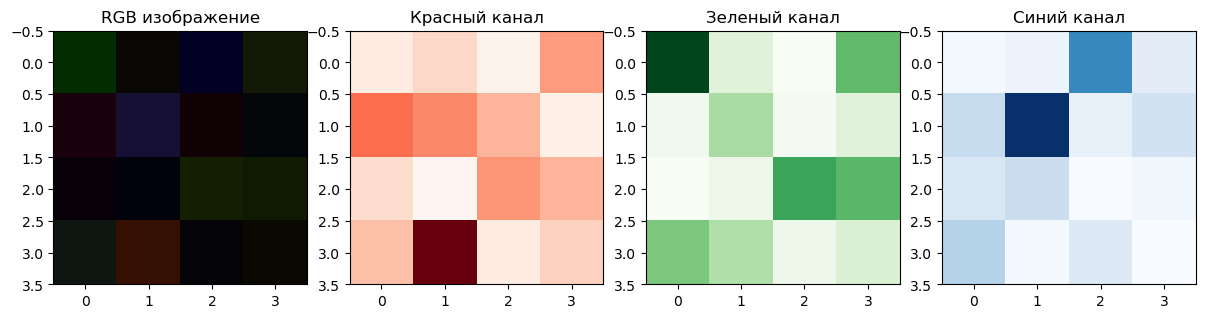

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(image)
axes[0].set_title('RGB изображение')
axes[1].imshow(image[:, :, 0], cmap='Reds')
axes[1].set_title('Красный канал')
axes[2].imshow(image[:, :, 1], cmap='Greens')
axes[2].set_title('Зеленый канал')
axes[3].imshow(image[:, :, 2], cmap='Blues')
axes[3].set_title('Синий канал')
plt.tight_layout()
plt.show()

In [9]:
from scipy import signal

In [27]:
image = np.array([
[3, 3, 2, 1, 0], [0, 0, 1, 3, 1], [3, 1, 2, 2, 3], [2, 0, 0, 2, 2], [2, 0, 0, 0, 1]
], dtype=np.float32)

In [28]:
# Фильтр (ядро) размером 3x3 - детектор линий
kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
], dtype=np.float32)

In [29]:
def simple_convolution(image, kernel, padding=0):
    """Выполняет операцию свертки с stride=1 и без padding (Valid)"""
    if padding > 0:
        image = np.pad(image, padding, mode='constant', constant_values=0)
    
    kernel_h, kernel_w = kernel.shape
    img_h, img_w = image.shape
    
    output_h = img_h - kernel_h + 1
    output_w = img_w - kernel_w + 1
    output = np.zeros((output_h, output_w))
    
    for i in range(output_h):
        for j in range(output_w):
            # Извлекаем область входного изображения
            region = image[i:i+kernel_h, j:j+kernel_w]
            # Поэлементное умножение и суммирование
            output[i, j] = np.sum(region * kernel)
    
    return output

In [30]:
# Применение свертки
result = simple_convolution(image, kernel, padding=0)

print("Входное изображение (5x5):")
print(image)
print("\nФильтр (3x3):")
print(kernel)
print("\nРезультат свертки (Valid padding):")
print(result)
print(f"Размер результата: {result.shape}")

Входное изображение (5x5):
[[3. 3. 2. 1. 0.]
 [0. 0. 1. 3. 1.]
 [3. 1. 2. 2. 3.]
 [2. 0. 0. 2. 2.]
 [2. 0. 0. 0. 1.]]

Фильтр (3x3):
[[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]

Результат свертки (Valid padding):
[[ 1. -2.  1.]
 [ 2. -6. -3.]
 [ 5. -3. -4.]]
Размер результата: (3, 3)


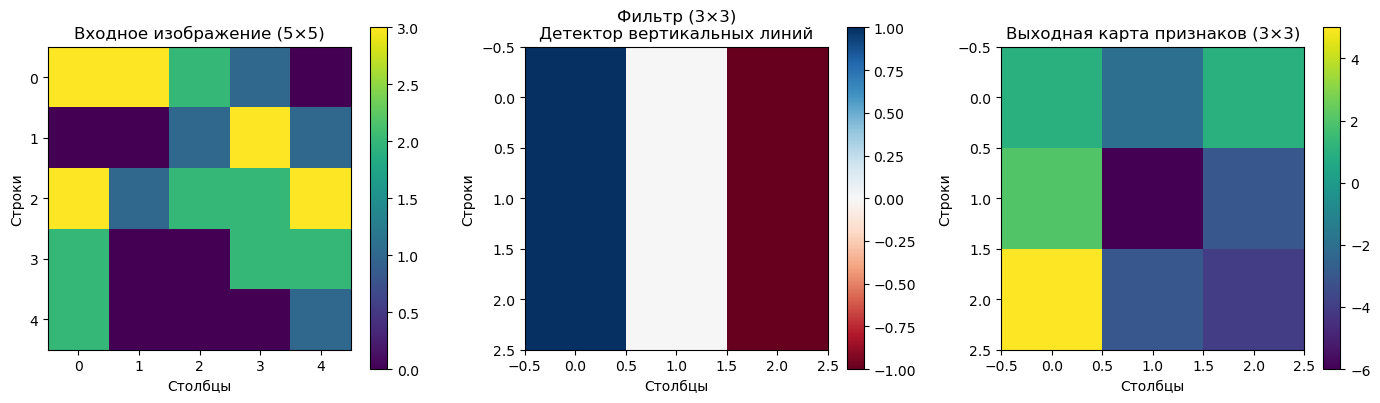


Пошаговое вычисление свертки:

Позиция [0,0]:
Область изображения:
[[3. 3. 2.]
 [0. 0. 1.]
 [3. 1. 2.]]
Результат: 1.0

Позиция [0,1]:
Область изображения:
[[3. 2. 1.]
 [0. 1. 3.]
 [1. 2. 2.]]
Результат: -2.0

Позиция [0,2]:
Область изображения:
[[2. 1. 0.]
 [1. 3. 1.]
 [2. 2. 3.]]
Результат: 1.0

Позиция [1,0]:
Область изображения:
[[0. 0. 1.]
 [3. 1. 2.]
 [2. 0. 0.]]
Результат: 2.0

Позиция [1,1]:
Область изображения:
[[0. 1. 3.]
 [1. 2. 2.]
 [0. 0. 2.]]
Результат: -6.0

Позиция [1,2]:
Область изображения:
[[1. 3. 1.]
 [2. 2. 3.]
 [0. 2. 2.]]
Результат: -3.0

Позиция [2,0]:
Область изображения:
[[3. 1. 2.]
 [2. 0. 0.]
 [2. 0. 0.]]
Результат: 5.0

Позиция [2,1]:
Область изображения:
[[1. 2. 2.]
 [0. 0. 2.]
 [0. 0. 0.]]
Результат: -3.0

Позиция [2,2]:
Область изображения:
[[2. 2. 3.]
 [0. 2. 2.]
 [0. 0. 1.]]
Результат: -4.0


In [31]:
# Визуализация процесса
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Входное изображение
im0 = axes[0].imshow(image, cmap='viridis')
axes[0].set_title('Входное изображение (5×5)')
axes[0].set_xlabel('Столбцы')
axes[0].set_ylabel('Строки')
plt.colorbar(im0, ax=axes[0])

# Фильтр
im1 = axes[1].imshow(kernel, cmap='RdBu')
axes[1].set_title('Фильтр (3×3)\nДетектор вертикальных линий')
axes[1].set_xlabel('Столбцы')
axes[1].set_ylabel('Строки')
plt.colorbar(im1, ax=axes[1])

# Результат
im2 = axes[2].imshow(result, cmap='viridis')
axes[2].set_title('Выходная карта признаков (3×3)')
axes[2].set_xlabel('Столбцы')
axes[2].set_ylabel('Строки')
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

# Демонстрация пошагового процесса
print("\n" + "="*50)
print("Пошаговое вычисление свертки:")
print("="*50)

for i in range(3):
    for j in range(3):
        region = image[i:i+3, j:j+3]
        result_val = np.sum(region * kernel)
        print(f"\nПозиция [{i},{j}]:")
        print(f"Область изображения:\n{region}")
        print(f"Результат: {result_val}")

## Примеры padding на Python

In [3]:
# Входное изображение 4x4
image = np.array([
[1, 2, 3, 4],
[5, 6, 7, 8],
[9, 10, 11, 12],
[13, 14, 15, 16]
], dtype=np.float32)
print("Исходное изображение (4×4):")
print(image)

Исходное изображение (4×4):
[[ 1.  2.  3.  4.]
 [ 5.  6.  7.  8.]
 [ 9. 10. 11. 12.]
 [13. 14. 15. 16.]]


In [4]:
# Padding = 1 (добавляем 1 слой нулей со всех сторон)
padded_1 = np.pad(image, pad_width=1, mode='constant', constant_values=0)
print("\nPadding = 1 (размер 6×6):")
print(padded_1)
# Padding = 2
padded_2 = np.pad(image, pad_width=2, mode='constant', constant_values=0)
print("\nPadding = 2 (размер 8×8):")
print(padded_2)


Padding = 1 (размер 6×6):
[[ 0.  0.  0.  0.  0.  0.]
 [ 0.  1.  2.  3.  4.  0.]
 [ 0.  5.  6.  7.  8.  0.]
 [ 0.  9. 10. 11. 12.  0.]
 [ 0. 13. 14. 15. 16.  0.]
 [ 0.  0.  0.  0.  0.  0.]]

Padding = 2 (размер 8×8):
[[ 0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  1.  2.  3.  4.  0.  0.]
 [ 0.  0.  5.  6.  7.  8.  0.  0.]
 [ 0.  0.  9. 10. 11. 12.  0.  0.]
 [ 0.  0. 13. 14. 15. 16.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.]]


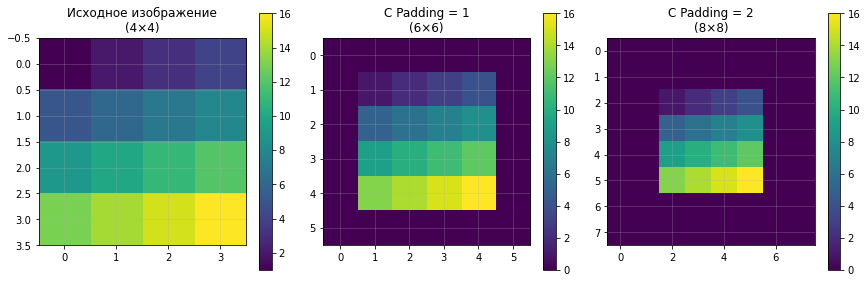

In [5]:
#Визуализация
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
im0 = axes[0].imshow(image, cmap='viridis')
axes[0].set_title('Исходное изображение\n(4×4)')
axes[0].grid(True, alpha=0.3)
plt.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(padded_1, cmap='viridis')
axes[1].set_title('С Padding = 1\n(6×6)')
axes[1].grid(True, alpha=0.3)
plt.colorbar(im1, ax=axes[1])
im2 = axes[2].imshow(padded_2, cmap='viridis')
axes[2].set_title('С Padding = 2\n(8×8)')
axes[2].grid(True, alpha=0.3)
plt.colorbar(im2, ax=axes[2])
plt.tight_layout()
plt.show()

In [8]:
# Демонстрация эффекта padding на размер выходного изображения
def calculate_output_size(input_size, kernel_size, padding, stride):
    return (input_size - kernel_size + 2*padding) // stride + 1

In [10]:
input_size = 32
kernel_size = 5
stride = 1
print("\n" + "="*50)
print("Влияние padding на размер выходного изображения:")
print("="*50)
print(f"Входное изображение: {input_size}×{input_size}")
print(f"Фильтр: {kernel_size}×{kernel_size}, stride: {stride}")
for padding in [0, 1, 2]:
    output_size = calculate_output_size(input_size, kernel_size, padding, stride)
    print(f" Padding = {padding} → выход {output_size}×{output_size}")


Влияние padding на размер выходного изображения:
Входное изображение: 32×32
Фильтр: 5×5, stride: 1
 Padding = 0 → выход 28×28
 Padding = 1 → выход 30×30
 Padding = 2 → выход 32×32


In [12]:
# Формула для расчета размера выхода свертки:
output_size = (input_size - kernel_size + 2*padding) / stride + 1
# Пример: Same padding
# Мы хотим, чтобы выход был того же размера, что и вход (5×5)
# 5 = (5 - 3 + 2*padding) / 1 + 1
# 4 = 5 - 3 + 2*padding
# 4 = 2 + 2*padding
# 2 = 2*padding
padding = 1
print("Пример Same Padding:")
print("Входное изображение: 5×5")
print("Фильтр: 3×3, stride: 1")
print("Required padding: 1")
print("Выходной размер: (5 - 3 + 2*1) / 1 + 1 = 5×5 ✓")

Пример Same Padding:
Входное изображение: 5×5
Фильтр: 3×3, stride: 1
Required padding: 1
Выходной размер: (5 - 3 + 2*1) / 1 + 1 = 5×5 ✓


## Примеры stride на Python

In [17]:
# Примеры stride на Python

import numpy as np
import matplotlib.pyplot as plt
# Функция выполняет операцию свертки с заданным stride и padding
def convolution_with_stride(image, kernel, stride=1, padding=0):

    if padding > 0:
        image = np.pad(image, pad_width=padding, mode='constant', constant_values=0)
    kernel_h, kernel_w = kernel.shape
    img_h, img_w = image.shape

    output_h = (img_h - kernel_h) // stride + 1
    output_w = (img_w - kernel_w) // stride + 1
    output = np.zeros((output_h, output_w))

    for i in range(0, img_h - kernel_h + 1, stride):
        for j in range(0, img_w - kernel_w + 1, stride):
            region = image[i:i+kernel_h, j:j+kernel_w]
            output[i//stride, j//stride] = np.sum(region * kernel)

    return output

In [18]:
# Входное изображение 8x8
image = np.array([
[1, 2, 3, 4, 5, 6, 7, 8],
[2, 3, 4, 5, 6, 7, 8, 9],
[3, 4, 5, 6, 7, 8, 9, 10],
[4, 5, 6, 7, 8, 9, 10, 11],
[5, 6, 7, 8, 9, 10, 11, 12],
[6, 7, 8, 9, 10, 11, 12, 13],
[7, 8, 9, 10, 11, 12, 13, 14],
[8, 9, 10, 11, 12, 13, 14, 15]
], dtype=np.float32)
# Простой фильтр для суммирования
kernel = np.array([
[1, 1],
[1, 1]
], dtype=np.float32)
# Применение свертки с различными stride
result_stride1 = convolution_with_stride(image, kernel, stride=1, padding=0)
result_stride2 = convolution_with_stride(image, kernel, stride=2, padding=0)
result_stride3 = convolution_with_stride(image, kernel, stride=3, padding=0)
print("Входное изображение (8×8):")
print(image)
print(f"\nРезультат с stride=1, размер: {result_stride1.shape}")
print(result_stride1)
print(f"\nРезультат с stride=2, размер: {result_stride2.shape}")
print(result_stride2)
print(f"\nРезультат с stride=3, размер: {result_stride3.shape}")
print(result_stride3)

Входное изображение (8×8):
[[ 1.  2.  3.  4.  5.  6.  7.  8.]
 [ 2.  3.  4.  5.  6.  7.  8.  9.]
 [ 3.  4.  5.  6.  7.  8.  9. 10.]
 [ 4.  5.  6.  7.  8.  9. 10. 11.]
 [ 5.  6.  7.  8.  9. 10. 11. 12.]
 [ 6.  7.  8.  9. 10. 11. 12. 13.]
 [ 7.  8.  9. 10. 11. 12. 13. 14.]
 [ 8.  9. 10. 11. 12. 13. 14. 15.]]

Результат с stride=1, размер: (7, 7)
[[ 8. 12. 16. 20. 24. 28. 32.]
 [12. 16. 20. 24. 28. 32. 36.]
 [16. 20. 24. 28. 32. 36. 40.]
 [20. 24. 28. 32. 36. 40. 44.]
 [24. 28. 32. 36. 40. 44. 48.]
 [28. 32. 36. 40. 44. 48. 52.]
 [32. 36. 40. 44. 48. 52. 56.]]

Результат с stride=2, размер: (4, 4)
[[ 8. 16. 24. 32.]
 [16. 24. 32. 40.]
 [24. 32. 40. 48.]
 [32. 40. 48. 56.]]

Результат с stride=3, размер: (3, 3)
[[ 8. 20. 32.]
 [20. 32. 44.]
 [32. 44. 56.]]


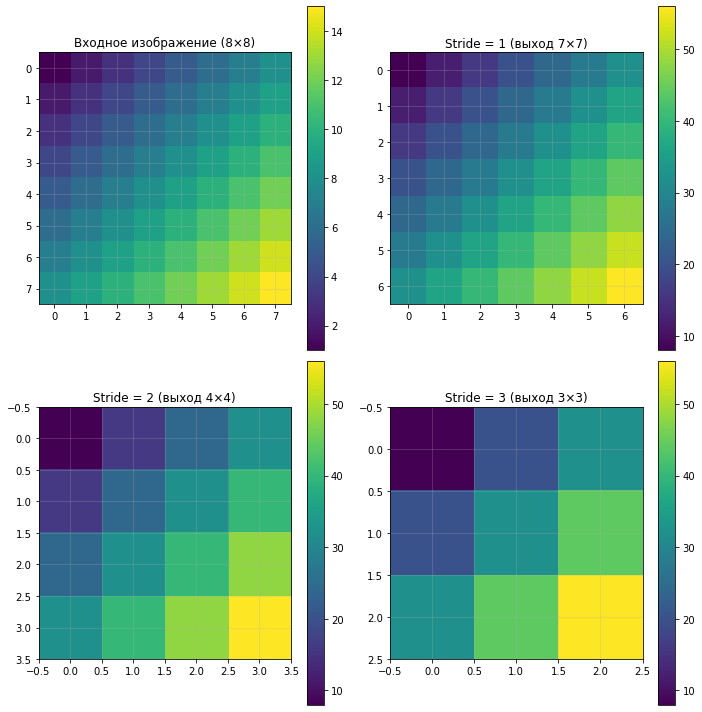

In [19]:
# Визуализация
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
im0 = axes[0, 0].imshow(image, cmap='viridis')
axes[0, 0].set_title('Входное изображение (8×8)')
axes[0, 0].grid(True, alpha=0.3)
plt.colorbar(im0, ax=axes[0, 0])
im1 = axes[0, 1].imshow(result_stride1, cmap='viridis')
axes[0, 1].set_title(f'Stride = 1 (выход {result_stride1.shape[0]}×{result_stride1.shape[1]})')
axes[0, 1].grid(True, alpha=0.3)
plt.colorbar(im1, ax=axes[0, 1])
im2 = axes[1, 0].imshow(result_stride2, cmap='viridis')
axes[1, 0].set_title(f'Stride = 2 (выход {result_stride2.shape[0]}×{result_stride2.shape[1]})')
axes[1, 0].grid(True, alpha=0.3)
plt.colorbar(im2, ax=axes[1, 0])
im3 = axes[1, 1].imshow(result_stride3, cmap='viridis')
axes[1, 1].set_title(f'Stride = 3 (выход {result_stride3.shape[0]}×{result_stride3.shape[1]})')
axes[1, 1].grid(True, alpha=0.3)
plt.colorbar(im3, ax=axes[1, 1])
plt.tight_layout()
plt.show()

In [24]:
# Формула размера выхода
print("\n" + "="*50)
print("Формула размера выходного изображения:")
print("=50")
print("output_size = (input_size - kernel_size + 2padding) / stride + 1")
print("\nПримеры:")
input_size = 8
kernel_size = 2
for stride in [1, 2, 3]:
    output_size = (input_size - kernel_size) // stride + 1
    print(f" stride={stride}: ({input_size} - {kernel_size}) / {stride} + 1 = {output_size}")


Формула размера выходного изображения:
=50
output_size = (input_size - kernel_size + 2padding) / stride + 1

Примеры:
 stride=1: (8 - 2) / 1 + 1 = 7
 stride=2: (8 - 2) / 2 + 1 = 4
 stride=3: (8 - 2) / 3 + 1 = 3


In [3]:
activations = np.array([
[12, 20, 30, 0],
[8, 12, 2, 0],
[34, 70, 37, 4],
[112, 100, 25, 12]
], dtype=np.float32)

In [6]:
def max_pooling(image, pool_size=2, stride=2):
    #"""Выполняет max pooling"""
    img_h, img_w = image.shape
    pool_h, pool_w = pool_size, pool_size
    output_h = (img_h - pool_h) // stride + 1
    output_w = (img_w - pool_w) // stride + 1
    output = np.zeros((output_h, output_w))

    for i in range(0, img_h - pool_h + 1, stride):
        for j in range(0, img_w - pool_w + 1, stride):
            window = image[i:i+pool_h, j:j+pool_w]
            output[i//stride, j//stride] = np.max(window)

    return output

In [7]:
def average_pooling(image, pool_size=2, stride=2):
    """Выполняет average pooling"""
    img_h, img_w = image.shape
    pool_h, pool_w = pool_size, pool_size
    output_h = (img_h - pool_h) // stride + 1
    output_w = (img_w - pool_w) // stride + 1
    output = np.zeros((output_h, output_w))

    for i in range(0, img_h - pool_h + 1, stride):
        for j in range(0, img_w - pool_w + 1, stride):
            window = image[i:i+pool_h, j:j+pool_w]
            output[i//stride, j//stride] = np.mean(window)

    return output

In [8]:
max_pool_result = max_pooling(activations, pool_size=2, stride=2)
avg_pool_result = average_pooling(activations, pool_size=2, stride=2)
print("Входная матрица активаций (4×4):")
print(activations)
print("\nMax Pooling (2×2, stride=2) (2×2):")
print(max_pool_result)
print("\nAverage Pooling (2×2, stride=2) (2×2):")
print(avg_pool_result)

Входная матрица активаций (4×4):
[[ 12.  20.  30.   0.]
 [  8.  12.   2.   0.]
 [ 34.  70.  37.   4.]
 [112. 100.  25.  12.]]

Max Pooling (2×2, stride=2) (2×2):
[[ 20.  30.]
 [112.  37.]]

Average Pooling (2×2, stride=2) (2×2):
[[13.   8. ]
 [79.  19.5]]


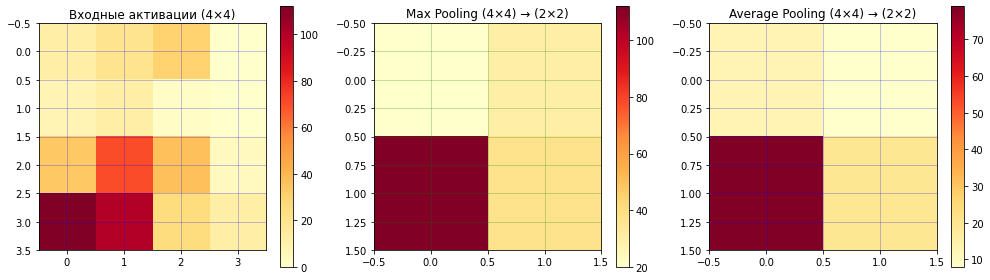

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
im0 = axes[0].imshow(activations, cmap='YlOrRd')
axes[0].set_title('Входные активации (4×4)')
axes[0].grid(True, alpha=0.3, color='blue')
plt.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(max_pool_result, cmap='YlOrRd')
axes[1].set_title('Max Pooling (4×4) → (2×2)')
axes[1].grid(True, alpha=0.3, color='blue')
plt.colorbar(im1, ax=axes[1])
im2 = axes[2].imshow(avg_pool_result, cmap='YlOrRd')
axes[2].set_title('Average Pooling (4×4) → (2×2)')
axes[2].grid(True, alpha=0.3, color='blue')
plt.colorbar(im2, ax=axes[2])
plt.tight_layout()
plt.show()